# AgriVision4 Grad-CAM and Error Analysis

This notebook evaluates every image in the locked validation split using the
seed-42 scratch checkpoints for WavestarNet and MobileViT-S. It writes complete
per-image Grad-CAM artifacts to disk and displays deterministic summaries inline.

Grad-CAM is a post-hoc localization method. Its maps indicate class-sensitive
spatial evidence but do not prove causal or clinically meaningful explanations.

In [1]:
import os
os.environ.setdefault("MPLCONFIGDIR", "/tmp/matplotlib")

import json
import platform
from dataclasses import replace
from pathlib import Path

import matplotlib
import nbformat
import numpy as np
import pandas as pd
import sklearn
import timm
import torch
import torchvision
from IPython.display import display

def find_repo_root(start: Path) -> Path:
    candidates = [start.resolve(), *start.resolve().parents]
    for candidate in candidates:
        if (candidate / "code" / "agrivision4" / "models" / "wavestarnet_family.py").is_file():
            return candidate
    raise FileNotFoundError("could not locate the Agrivision4 repository root")

REPO_ROOT = find_repo_root(Path.cwd())
CODE_ROOT = REPO_ROOT / "code"
import sys
if str(CODE_ROOT) not in sys.path:
    sys.path.insert(0, str(CODE_ROOT))
os.chdir(REPO_ROOT)

from agrivision4.interpretability.gradcam_analysis import (
    default_config,
    display_analysis_report,
    run_analysis,
    verify_real_inputs,
)

environment = {
    "python": platform.python_version(),
    "torch": torch.__version__,
    "torchvision": torchvision.__version__,
    "timm": timm.__version__,
    "numpy": np.__version__,
    "pandas": pd.__version__,
    "sklearn": sklearn.__version__,
    "matplotlib": matplotlib.__version__,
    "device": "cpu",
}
display(pd.DataFrame([environment]))

,python,torch,torchvision,timm,numpy,pandas,sklearn,matplotlib,device
0,3.11.15,2.12.1+cpu,0.27.1+cpu,1.0.27,2.4.4,3.0.3,1.9.0,3.11.1,cpu


## Configuration

In [2]:
RUN_MODE = "full"  # "verify" processes two images; "full" processes all 915.
VERIFY_LIMIT = 2
INLINE_EXAMPLES_PER_CATEGORY = 4
PROGRESS_INTERVAL = 10

if RUN_MODE not in {"verify", "full"}:
    raise ValueError("RUN_MODE must be 'verify' or 'full'")

base_config = default_config(REPO_ROOT)
output_dir = base_config.output_dir
if RUN_MODE == "verify":
    output_dir = output_dir.with_name("gradcam_validation_v1_verify")
config = replace(
    base_config,
    output_dir=output_dir,
    inline_examples_per_category=INLINE_EXAMPLES_PER_CATEGORY,
    progress_interval=PROGRESS_INTERVAL,
)

configuration = {
    "run_mode": RUN_MODE,
    "verification_limit": VERIFY_LIMIT,
    "validation_manifest": str(config.validation_csv),
    "class_mapping": str(config.class_mapping_json),
    "image_zip": str(config.image_zip),
    "checkpoint_zip": str(config.checkpoint_zip),
    "output_dir": str(config.output_dir),
    "seed": config.seed,
    "image_size": config.image_size,
}
print(json.dumps(configuration, indent=2), flush=True)

{
  "run_mode": "full",
  "verification_limit": 2,
  "validation_manifest": "/run/media/sha-weed/adc6c87e-0116-4a25-a6e9-8555193c1e51/Research/Agrivision4/agrivision4/research_protocol/agrivision4-locked-validation-v1/manifests/validation.csv",
  "class_mapping": "/run/media/sha-weed/adc6c87e-0116-4a25-a6e9-8555193c1e51/Research/Agrivision4/agrivision4/research_protocol/agrivision4-locked-validation-v1/manifests/class_mapping.json",
  "image_zip": "/run/media/sha-weed/adc6c87e-0116-4a25-a6e9-8555193c1e51/Research/Agrivision4/agrivision4/cleaned_kaggle/agrivision4-clean-grouped-v1/agrivision4-clean-grouped-images.zip",
  "checkpoint_zip": "/run/media/sha-weed/adc6c87e-0116-4a25-a6e9-8555193c1e51/Research/Agrivision4/agrivision4/results wavestarnet.zip",
  "output_dir": "/run/media/sha-weed/adc6c87e-0116-4a25-a6e9-8555193c1e51/Research/Agrivision4/agrivision4/results/interpretability/gradcam_validation_v1",
  "seed": 42,
  "image_size": 224
}


## Preflight Verification

In [3]:
verification = verify_real_inputs(config, sample_limit=VERIFY_LIMIT)
assert len(verification) == VERIFY_LIMIT * 2
assert verification["reference_prediction_match"].all()
assert verification["predicted_cam_finite"].all()
assert verification["ground_truth_cam_finite"].all()
assert verification["maximum_probability_error"].max() <= 1e-5
display(verification)
print("Preflight verification passed.", flush=True)

,sample_id,model_key,checkpoint_sha256,target_layers,input_shape,cam_shape,predicted_label_id,reference_prediction_match,maximum_probability_error,predicted_cam_finite,ground_truth_cam_finite
0,clean_000001,wavestarnet_big_transfer_v2,6aad03be256fbf5d6227375bffad9961a3a69f40454755...,"stage_2, stage_3, stage_4","(1, 3, 224, 224)","(224, 224)",0,True,2.213256e-08,True,True
1,clean_000001,mobilevit_s,fb9c8dc2b88a7d3a92805fa92095a2940a56df0db3d75f...,final_conv,"(1, 3, 224, 224)","(224, 224)",0,True,4.492355e-07,True,True
2,clean_000005,wavestarnet_big_transfer_v2,6aad03be256fbf5d6227375bffad9961a3a69f40454755...,"stage_2, stage_3, stage_4","(1, 3, 224, 224)","(224, 224)",6,True,1.880320e-07,True,True
3,clean_000005,mobilevit_s,fb9c8dc2b88a7d3a92805fa92095a2940a56df0db3d75f...,final_conv,"(1, 3, 224, 224)","(224, 224)",6,True,3.790382e-07,True,True


Preflight verification passed.


## Full Locked-Validation Analysis

In [4]:
analysis_limit = VERIFY_LIMIT if RUN_MODE == "verify" else None
summary = run_analysis(config, limit=analysis_limit)
print(summary, flush=True)

{"completed": 10, "elapsed_seconds": 1.586, "estimated_remaining_seconds": 288.682, "event": "gradcam_progress", "records_per_second": 6.3045, "total": 1830}


{"completed": 20, "elapsed_seconds": 3.156, "estimated_remaining_seconds": 285.598, "event": "gradcam_progress", "records_per_second": 6.3376, "total": 1830}


{"completed": 30, "elapsed_seconds": 4.68, "estimated_remaining_seconds": 280.798, "event": "gradcam_progress", "records_per_second": 6.4103, "total": 1830}


{"completed": 40, "elapsed_seconds": 6.896, "estimated_remaining_seconds": 308.618, "event": "gradcam_progress", "records_per_second": 5.8001, "total": 1830}


{"completed": 50, "elapsed_seconds": 8.807, "estimated_remaining_seconds": 313.542, "event": "gradcam_progress", "records_per_second": 5.6771, "total": 1830}


{"completed": 60, "elapsed_seconds": 10.403, "estimated_remaining_seconds": 306.894, "event": "gradcam_progress", "records_per_second": 5.7675, "total": 1830}


{"completed": 70, "elapsed_seconds": 12.405, "estimated_remaining_seconds": 311.901, "event": "gradcam_progress", "records_per_second": 5.6428, "total": 1830}


{"completed": 80, "elapsed_seconds": 16.076, "estimated_remaining_seconds": 351.671, "event": "gradcam_progress", "records_per_second": 4.9762, "total": 1830}


{"completed": 90, "elapsed_seconds": 17.723, "estimated_remaining_seconds": 342.642, "event": "gradcam_progress", "records_per_second": 5.0782, "total": 1830}


{"completed": 100, "elapsed_seconds": 19.53, "estimated_remaining_seconds": 337.876, "event": "gradcam_progress", "records_per_second": 5.1202, "total": 1830}


{"completed": 110, "elapsed_seconds": 21.435, "estimated_remaining_seconds": 335.165, "event": "gradcam_progress", "records_per_second": 5.1318, "total": 1830}


{"completed": 120, "elapsed_seconds": 23.137, "estimated_remaining_seconds": 329.703, "event": "gradcam_progress", "records_per_second": 5.1865, "total": 1830}


{"completed": 130, "elapsed_seconds": 25.254, "estimated_remaining_seconds": 330.249, "event": "gradcam_progress", "records_per_second": 5.1476, "total": 1830}


{"completed": 140, "elapsed_seconds": 26.926, "estimated_remaining_seconds": 325.039, "event": "gradcam_progress", "records_per_second": 5.1994, "total": 1830}


{"completed": 150, "elapsed_seconds": 28.482, "estimated_remaining_seconds": 318.999, "event": "gradcam_progress", "records_per_second": 5.2665, "total": 1830}


{"completed": 160, "elapsed_seconds": 30.073, "estimated_remaining_seconds": 313.89, "event": "gradcam_progress", "records_per_second": 5.3203, "total": 1830}


{"completed": 170, "elapsed_seconds": 31.887, "estimated_remaining_seconds": 311.371, "event": "gradcam_progress", "records_per_second": 5.3313, "total": 1830}


{"completed": 180, "elapsed_seconds": 33.573, "estimated_remaining_seconds": 307.753, "event": "gradcam_progress", "records_per_second": 5.3614, "total": 1830}


{"completed": 190, "elapsed_seconds": 35.521, "estimated_remaining_seconds": 306.599, "event": "gradcam_progress", "records_per_second": 5.349, "total": 1830}


{"completed": 200, "elapsed_seconds": 37.506, "estimated_remaining_seconds": 305.672, "event": "gradcam_progress", "records_per_second": 5.3325, "total": 1830}


{"completed": 210, "elapsed_seconds": 39.174, "estimated_remaining_seconds": 302.201, "event": "gradcam_progress", "records_per_second": 5.3607, "total": 1830}


{"completed": 220, "elapsed_seconds": 40.784, "estimated_remaining_seconds": 298.465, "event": "gradcam_progress", "records_per_second": 5.3943, "total": 1830}


{"completed": 230, "elapsed_seconds": 42.852, "estimated_remaining_seconds": 298.104, "event": "gradcam_progress", "records_per_second": 5.3673, "total": 1830}


{"completed": 240, "elapsed_seconds": 44.713, "estimated_remaining_seconds": 296.227, "event": "gradcam_progress", "records_per_second": 5.3675, "total": 1830}


{"completed": 250, "elapsed_seconds": 46.539, "estimated_remaining_seconds": 294.126, "event": "gradcam_progress", "records_per_second": 5.3718, "total": 1830}


{"completed": 260, "elapsed_seconds": 48.757, "estimated_remaining_seconds": 294.417, "event": "gradcam_progress", "records_per_second": 5.3326, "total": 1830}


{"completed": 270, "elapsed_seconds": 50.746, "estimated_remaining_seconds": 293.2, "event": "gradcam_progress", "records_per_second": 5.3206, "total": 1830}


{"completed": 280, "elapsed_seconds": 52.303, "estimated_remaining_seconds": 289.535, "event": "gradcam_progress", "records_per_second": 5.3534, "total": 1830}


{"completed": 290, "elapsed_seconds": 53.946, "estimated_remaining_seconds": 286.471, "event": "gradcam_progress", "records_per_second": 5.3758, "total": 1830}


{"completed": 300, "elapsed_seconds": 56.325, "estimated_remaining_seconds": 287.259, "event": "gradcam_progress", "records_per_second": 5.3262, "total": 1830}


{"completed": 310, "elapsed_seconds": 58.348, "estimated_remaining_seconds": 286.094, "event": "gradcam_progress", "records_per_second": 5.3129, "total": 1830}


{"completed": 320, "elapsed_seconds": 60.133, "estimated_remaining_seconds": 283.754, "event": "gradcam_progress", "records_per_second": 5.3215, "total": 1830}


{"completed": 330, "elapsed_seconds": 61.653, "estimated_remaining_seconds": 280.241, "event": "gradcam_progress", "records_per_second": 5.3525, "total": 1830}


{"completed": 340, "elapsed_seconds": 63.362, "estimated_remaining_seconds": 277.674, "event": "gradcam_progress", "records_per_second": 5.366, "total": 1830}


{"completed": 350, "elapsed_seconds": 65.227, "estimated_remaining_seconds": 275.818, "event": "gradcam_progress", "records_per_second": 5.3659, "total": 1830}


{"completed": 360, "elapsed_seconds": 67.453, "estimated_remaining_seconds": 275.432, "event": "gradcam_progress", "records_per_second": 5.3371, "total": 1830}


{"completed": 370, "elapsed_seconds": 69.331, "estimated_remaining_seconds": 273.575, "event": "gradcam_progress", "records_per_second": 5.3368, "total": 1830}


{"completed": 380, "elapsed_seconds": 71.23, "estimated_remaining_seconds": 271.797, "event": "gradcam_progress", "records_per_second": 5.3349, "total": 1830}


{"completed": 390, "elapsed_seconds": 73.119, "estimated_remaining_seconds": 269.977, "event": "gradcam_progress", "records_per_second": 5.3338, "total": 1830}


{"completed": 400, "elapsed_seconds": 74.843, "estimated_remaining_seconds": 267.565, "event": "gradcam_progress", "records_per_second": 5.3445, "total": 1830}


{"completed": 410, "elapsed_seconds": 76.558, "estimated_remaining_seconds": 265.151, "event": "gradcam_progress", "records_per_second": 5.3554, "total": 1830}


{"completed": 420, "elapsed_seconds": 78.513, "estimated_remaining_seconds": 263.58, "event": "gradcam_progress", "records_per_second": 5.3494, "total": 1830}


{"completed": 430, "elapsed_seconds": 80.192, "estimated_remaining_seconds": 261.092, "event": "gradcam_progress", "records_per_second": 5.3621, "total": 1830}


{"completed": 440, "elapsed_seconds": 82.49, "estimated_remaining_seconds": 260.592, "event": "gradcam_progress", "records_per_second": 5.334, "total": 1830}


{"completed": 450, "elapsed_seconds": 84.274, "estimated_remaining_seconds": 258.441, "event": "gradcam_progress", "records_per_second": 5.3397, "total": 1830}


{"completed": 460, "elapsed_seconds": 85.919, "estimated_remaining_seconds": 255.891, "event": "gradcam_progress", "records_per_second": 5.3538, "total": 1830}


{"completed": 470, "elapsed_seconds": 87.724, "estimated_remaining_seconds": 253.839, "event": "gradcam_progress", "records_per_second": 5.3577, "total": 1830}


{"completed": 480, "elapsed_seconds": 89.619, "estimated_remaining_seconds": 252.053, "event": "gradcam_progress", "records_per_second": 5.356, "total": 1830}


{"completed": 490, "elapsed_seconds": 91.752, "estimated_remaining_seconds": 250.914, "event": "gradcam_progress", "records_per_second": 5.3405, "total": 1830}


{"completed": 500, "elapsed_seconds": 93.377, "estimated_remaining_seconds": 248.382, "event": "gradcam_progress", "records_per_second": 5.3546, "total": 1830}


{"completed": 510, "elapsed_seconds": 95.476, "estimated_remaining_seconds": 247.115, "event": "gradcam_progress", "records_per_second": 5.3416, "total": 1830}


{"completed": 520, "elapsed_seconds": 97.524, "estimated_remaining_seconds": 245.685, "event": "gradcam_progress", "records_per_second": 5.332, "total": 1830}


{"completed": 530, "elapsed_seconds": 99.61, "estimated_remaining_seconds": 244.327, "event": "gradcam_progress", "records_per_second": 5.3207, "total": 1830}


{"completed": 540, "elapsed_seconds": 101.171, "estimated_remaining_seconds": 241.685, "event": "gradcam_progress", "records_per_second": 5.3375, "total": 1830}


{"completed": 550, "elapsed_seconds": 102.658, "estimated_remaining_seconds": 238.914, "event": "gradcam_progress", "records_per_second": 5.3576, "total": 1830}


{"completed": 560, "elapsed_seconds": 104.384, "estimated_remaining_seconds": 236.727, "event": "gradcam_progress", "records_per_second": 5.3648, "total": 1830}


{"completed": 570, "elapsed_seconds": 105.979, "estimated_remaining_seconds": 234.268, "event": "gradcam_progress", "records_per_second": 5.3784, "total": 1830}


{"completed": 580, "elapsed_seconds": 107.627, "estimated_remaining_seconds": 231.955, "event": "gradcam_progress", "records_per_second": 5.389, "total": 1830}


{"completed": 590, "elapsed_seconds": 109.673, "estimated_remaining_seconds": 230.499, "event": "gradcam_progress", "records_per_second": 5.3796, "total": 1830}


{"completed": 600, "elapsed_seconds": 111.446, "estimated_remaining_seconds": 228.465, "event": "gradcam_progress", "records_per_second": 5.3838, "total": 1830}


{"completed": 610, "elapsed_seconds": 113.117, "estimated_remaining_seconds": 226.234, "event": "gradcam_progress", "records_per_second": 5.3927, "total": 1830}


{"completed": 620, "elapsed_seconds": 114.701, "estimated_remaining_seconds": 223.852, "event": "gradcam_progress", "records_per_second": 5.4054, "total": 1830}


{"completed": 630, "elapsed_seconds": 116.22, "estimated_remaining_seconds": 221.372, "event": "gradcam_progress", "records_per_second": 5.4208, "total": 1830}


{"completed": 640, "elapsed_seconds": 117.64, "estimated_remaining_seconds": 218.737, "event": "gradcam_progress", "records_per_second": 5.4403, "total": 1830}


{"completed": 650, "elapsed_seconds": 119.117, "estimated_remaining_seconds": 216.243, "event": "gradcam_progress", "records_per_second": 5.4568, "total": 1830}


{"completed": 660, "elapsed_seconds": 120.531, "estimated_remaining_seconds": 213.668, "event": "gradcam_progress", "records_per_second": 5.4758, "total": 1830}


{"completed": 670, "elapsed_seconds": 121.972, "estimated_remaining_seconds": 211.175, "event": "gradcam_progress", "records_per_second": 5.4931, "total": 1830}


{"completed": 680, "elapsed_seconds": 123.465, "estimated_remaining_seconds": 208.8, "event": "gradcam_progress", "records_per_second": 5.5077, "total": 1830}


{"completed": 690, "elapsed_seconds": 124.875, "estimated_remaining_seconds": 206.315, "event": "gradcam_progress", "records_per_second": 5.5255, "total": 1830}


{"completed": 700, "elapsed_seconds": 126.532, "estimated_remaining_seconds": 204.258, "event": "gradcam_progress", "records_per_second": 5.5322, "total": 1830}


{"completed": 710, "elapsed_seconds": 128.391, "estimated_remaining_seconds": 202.532, "event": "gradcam_progress", "records_per_second": 5.53, "total": 1830}


{"completed": 720, "elapsed_seconds": 130.581, "estimated_remaining_seconds": 201.313, "event": "gradcam_progress", "records_per_second": 5.5138, "total": 1830}


{"completed": 730, "elapsed_seconds": 133.078, "estimated_remaining_seconds": 200.529, "event": "gradcam_progress", "records_per_second": 5.4855, "total": 1830}


{"completed": 740, "elapsed_seconds": 134.836, "estimated_remaining_seconds": 198.61, "event": "gradcam_progress", "records_per_second": 5.4881, "total": 1830}


{"completed": 750, "elapsed_seconds": 136.651, "estimated_remaining_seconds": 196.777, "event": "gradcam_progress", "records_per_second": 5.4884, "total": 1830}


{"completed": 760, "elapsed_seconds": 138.316, "estimated_remaining_seconds": 194.734, "event": "gradcam_progress", "records_per_second": 5.4947, "total": 1830}


{"completed": 770, "elapsed_seconds": 139.967, "estimated_remaining_seconds": 192.681, "event": "gradcam_progress", "records_per_second": 5.5013, "total": 1830}


{"completed": 780, "elapsed_seconds": 141.614, "estimated_remaining_seconds": 190.634, "event": "gradcam_progress", "records_per_second": 5.5079, "total": 1830}


{"completed": 790, "elapsed_seconds": 143.32, "estimated_remaining_seconds": 188.674, "event": "gradcam_progress", "records_per_second": 5.5121, "total": 1830}


{"completed": 800, "elapsed_seconds": 144.868, "estimated_remaining_seconds": 186.517, "event": "gradcam_progress", "records_per_second": 5.5223, "total": 1830}


{"completed": 810, "elapsed_seconds": 146.651, "estimated_remaining_seconds": 184.671, "event": "gradcam_progress", "records_per_second": 5.5233, "total": 1830}


{"completed": 820, "elapsed_seconds": 148.326, "estimated_remaining_seconds": 182.694, "event": "gradcam_progress", "records_per_second": 5.5284, "total": 1830}


{"completed": 830, "elapsed_seconds": 150.05, "estimated_remaining_seconds": 180.783, "event": "gradcam_progress", "records_per_second": 5.5315, "total": 1830}


{"completed": 840, "elapsed_seconds": 152.049, "estimated_remaining_seconds": 179.2, "event": "gradcam_progress", "records_per_second": 5.5246, "total": 1830}


{"completed": 850, "elapsed_seconds": 153.979, "estimated_remaining_seconds": 177.528, "event": "gradcam_progress", "records_per_second": 5.5202, "total": 1830}


{"completed": 860, "elapsed_seconds": 155.55, "estimated_remaining_seconds": 175.446, "event": "gradcam_progress", "records_per_second": 5.5288, "total": 1830}


{"completed": 870, "elapsed_seconds": 157.164, "estimated_remaining_seconds": 173.423, "event": "gradcam_progress", "records_per_second": 5.5356, "total": 1830}


{"completed": 880, "elapsed_seconds": 159.047, "estimated_remaining_seconds": 171.699, "event": "gradcam_progress", "records_per_second": 5.5329, "total": 1830}


{"completed": 890, "elapsed_seconds": 160.776, "estimated_remaining_seconds": 169.809, "event": "gradcam_progress", "records_per_second": 5.5356, "total": 1830}


{"completed": 900, "elapsed_seconds": 162.588, "estimated_remaining_seconds": 168.007, "event": "gradcam_progress", "records_per_second": 5.5355, "total": 1830}


{"completed": 910, "elapsed_seconds": 164.201, "estimated_remaining_seconds": 166.005, "event": "gradcam_progress", "records_per_second": 5.542, "total": 1830}


{"completed": 920, "elapsed_seconds": 165.745, "estimated_remaining_seconds": 163.944, "event": "gradcam_progress", "records_per_second": 5.5507, "total": 1830}


{"completed": 930, "elapsed_seconds": 167.344, "estimated_remaining_seconds": 161.946, "event": "gradcam_progress", "records_per_second": 5.5574, "total": 1830}


{"completed": 940, "elapsed_seconds": 169.186, "estimated_remaining_seconds": 160.187, "event": "gradcam_progress", "records_per_second": 5.556, "total": 1830}


{"completed": 950, "elapsed_seconds": 170.964, "estimated_remaining_seconds": 158.367, "event": "gradcam_progress", "records_per_second": 5.5567, "total": 1830}


{"completed": 960, "elapsed_seconds": 172.624, "estimated_remaining_seconds": 156.44, "event": "gradcam_progress", "records_per_second": 5.5612, "total": 1830}


{"completed": 970, "elapsed_seconds": 174.258, "estimated_remaining_seconds": 154.497, "event": "gradcam_progress", "records_per_second": 5.5664, "total": 1830}


{"completed": 980, "elapsed_seconds": 176.009, "estimated_remaining_seconds": 152.661, "event": "gradcam_progress", "records_per_second": 5.5679, "total": 1830}


{"completed": 990, "elapsed_seconds": 177.731, "estimated_remaining_seconds": 150.802, "event": "gradcam_progress", "records_per_second": 5.5702, "total": 1830}


{"completed": 1000, "elapsed_seconds": 180.038, "estimated_remaining_seconds": 149.432, "event": "gradcam_progress", "records_per_second": 5.5544, "total": 1830}


{"completed": 1010, "elapsed_seconds": 181.723, "estimated_remaining_seconds": 147.537, "event": "gradcam_progress", "records_per_second": 5.5579, "total": 1830}


{"completed": 1020, "elapsed_seconds": 183.734, "estimated_remaining_seconds": 145.907, "event": "gradcam_progress", "records_per_second": 5.5515, "total": 1830}


{"completed": 1030, "elapsed_seconds": 185.979, "estimated_remaining_seconds": 144.449, "event": "gradcam_progress", "records_per_second": 5.5383, "total": 1830}


{"completed": 1040, "elapsed_seconds": 188.024, "estimated_remaining_seconds": 142.826, "event": "gradcam_progress", "records_per_second": 5.5312, "total": 1830}


{"completed": 1050, "elapsed_seconds": 190.064, "estimated_remaining_seconds": 141.19, "event": "gradcam_progress", "records_per_second": 5.5245, "total": 1830}


{"completed": 1060, "elapsed_seconds": 191.737, "estimated_remaining_seconds": 139.281, "event": "gradcam_progress", "records_per_second": 5.5284, "total": 1830}


{"completed": 1070, "elapsed_seconds": 193.612, "estimated_remaining_seconds": 137.519, "event": "gradcam_progress", "records_per_second": 5.5265, "total": 1830}


{"completed": 1080, "elapsed_seconds": 195.327, "estimated_remaining_seconds": 135.644, "event": "gradcam_progress", "records_per_second": 5.5292, "total": 1830}


{"completed": 1090, "elapsed_seconds": 196.961, "estimated_remaining_seconds": 133.717, "event": "gradcam_progress", "records_per_second": 5.5341, "total": 1830}


{"completed": 1100, "elapsed_seconds": 198.87, "estimated_remaining_seconds": 131.977, "event": "gradcam_progress", "records_per_second": 5.5313, "total": 1830}


{"completed": 1110, "elapsed_seconds": 200.85, "estimated_remaining_seconds": 130.281, "event": "gradcam_progress", "records_per_second": 5.5265, "total": 1830}


{"completed": 1120, "elapsed_seconds": 202.827, "estimated_remaining_seconds": 128.578, "event": "gradcam_progress", "records_per_second": 5.5219, "total": 1830}


{"completed": 1130, "elapsed_seconds": 205.041, "estimated_remaining_seconds": 127.017, "event": "gradcam_progress", "records_per_second": 5.5111, "total": 1830}


{"completed": 1140, "elapsed_seconds": 206.743, "estimated_remaining_seconds": 125.134, "event": "gradcam_progress", "records_per_second": 5.5141, "total": 1830}


{"completed": 1150, "elapsed_seconds": 208.455, "estimated_remaining_seconds": 123.26, "event": "gradcam_progress", "records_per_second": 5.5168, "total": 1830}


{"completed": 1160, "elapsed_seconds": 210.105, "estimated_remaining_seconds": 121.354, "event": "gradcam_progress", "records_per_second": 5.5211, "total": 1830}


{"completed": 1170, "elapsed_seconds": 212.073, "estimated_remaining_seconds": 119.631, "event": "gradcam_progress", "records_per_second": 5.517, "total": 1830}


{"completed": 1180, "elapsed_seconds": 213.884, "estimated_remaining_seconds": 117.817, "event": "gradcam_progress", "records_per_second": 5.517, "total": 1830}


{"completed": 1190, "elapsed_seconds": 215.507, "estimated_remaining_seconds": 115.903, "event": "gradcam_progress", "records_per_second": 5.5219, "total": 1830}


{"completed": 1200, "elapsed_seconds": 217.144, "estimated_remaining_seconds": 114.001, "event": "gradcam_progress", "records_per_second": 5.5263, "total": 1830}


{"completed": 1210, "elapsed_seconds": 218.712, "estimated_remaining_seconds": 112.067, "event": "gradcam_progress", "records_per_second": 5.5324, "total": 1830}


{"completed": 1220, "elapsed_seconds": 220.329, "estimated_remaining_seconds": 110.164, "event": "gradcam_progress", "records_per_second": 5.5372, "total": 1830}


{"completed": 1230, "elapsed_seconds": 222.047, "estimated_remaining_seconds": 108.316, "event": "gradcam_progress", "records_per_second": 5.5394, "total": 1830}


{"completed": 1240, "elapsed_seconds": 224.417, "estimated_remaining_seconds": 106.779, "event": "gradcam_progress", "records_per_second": 5.5254, "total": 1830}


{"completed": 1250, "elapsed_seconds": 225.99, "estimated_remaining_seconds": 104.859, "event": "gradcam_progress", "records_per_second": 5.5312, "total": 1830}


{"completed": 1260, "elapsed_seconds": 227.401, "estimated_remaining_seconds": 102.872, "event": "gradcam_progress", "records_per_second": 5.5409, "total": 1830}


{"completed": 1270, "elapsed_seconds": 228.874, "estimated_remaining_seconds": 100.921, "event": "gradcam_progress", "records_per_second": 5.5489, "total": 1830}


{"completed": 1280, "elapsed_seconds": 230.39, "estimated_remaining_seconds": 98.996, "event": "gradcam_progress", "records_per_second": 5.5558, "total": 1830}


{"completed": 1290, "elapsed_seconds": 232.138, "estimated_remaining_seconds": 97.174, "event": "gradcam_progress", "records_per_second": 5.557, "total": 1830}


{"completed": 1300, "elapsed_seconds": 233.676, "estimated_remaining_seconds": 95.268, "event": "gradcam_progress", "records_per_second": 5.5633, "total": 1830}


{"completed": 1310, "elapsed_seconds": 235.327, "estimated_remaining_seconds": 93.412, "event": "gradcam_progress", "records_per_second": 5.5667, "total": 1830}


{"completed": 1320, "elapsed_seconds": 236.794, "estimated_remaining_seconds": 91.489, "event": "gradcam_progress", "records_per_second": 5.5745, "total": 1830}


{"completed": 1330, "elapsed_seconds": 238.483, "estimated_remaining_seconds": 89.655, "event": "gradcam_progress", "records_per_second": 5.5769, "total": 1830}


{"completed": 1340, "elapsed_seconds": 240.144, "estimated_remaining_seconds": 87.814, "event": "gradcam_progress", "records_per_second": 5.58, "total": 1830}


{"completed": 1350, "elapsed_seconds": 242.069, "estimated_remaining_seconds": 86.069, "event": "gradcam_progress", "records_per_second": 5.5769, "total": 1830}


{"completed": 1360, "elapsed_seconds": 244.577, "estimated_remaining_seconds": 84.523, "event": "gradcam_progress", "records_per_second": 5.5606, "total": 1830}


{"completed": 1370, "elapsed_seconds": 246.334, "estimated_remaining_seconds": 82.711, "event": "gradcam_progress", "records_per_second": 5.5616, "total": 1830}


{"completed": 1380, "elapsed_seconds": 249.075, "estimated_remaining_seconds": 81.22, "event": "gradcam_progress", "records_per_second": 5.5405, "total": 1830}


{"completed": 1390, "elapsed_seconds": 251.101, "estimated_remaining_seconds": 79.485, "event": "gradcam_progress", "records_per_second": 5.5356, "total": 1830}


{"completed": 1400, "elapsed_seconds": 253.161, "estimated_remaining_seconds": 77.757, "event": "gradcam_progress", "records_per_second": 5.5301, "total": 1830}


{"completed": 1410, "elapsed_seconds": 255.456, "estimated_remaining_seconds": 76.093, "event": "gradcam_progress", "records_per_second": 5.5195, "total": 1830}


{"completed": 1420, "elapsed_seconds": 257.22, "estimated_remaining_seconds": 74.268, "event": "gradcam_progress", "records_per_second": 5.5206, "total": 1830}


{"completed": 1430, "elapsed_seconds": 258.839, "estimated_remaining_seconds": 72.403, "event": "gradcam_progress", "records_per_second": 5.5247, "total": 1830}


{"completed": 1440, "elapsed_seconds": 260.493, "estimated_remaining_seconds": 70.55, "event": "gradcam_progress", "records_per_second": 5.528, "total": 1830}


{"completed": 1450, "elapsed_seconds": 262.241, "estimated_remaining_seconds": 68.725, "event": "gradcam_progress", "records_per_second": 5.5293, "total": 1830}


{"completed": 1460, "elapsed_seconds": 263.956, "estimated_remaining_seconds": 66.893, "event": "gradcam_progress", "records_per_second": 5.5312, "total": 1830}


{"completed": 1470, "elapsed_seconds": 265.551, "estimated_remaining_seconds": 65.033, "event": "gradcam_progress", "records_per_second": 5.5357, "total": 1830}


{"completed": 1480, "elapsed_seconds": 267.056, "estimated_remaining_seconds": 63.155, "event": "gradcam_progress", "records_per_second": 5.5419, "total": 1830}


{"completed": 1490, "elapsed_seconds": 268.646, "estimated_remaining_seconds": 61.302, "event": "gradcam_progress", "records_per_second": 5.5463, "total": 1830}


{"completed": 1500, "elapsed_seconds": 270.195, "estimated_remaining_seconds": 59.443, "event": "gradcam_progress", "records_per_second": 5.5515, "total": 1830}


{"completed": 1510, "elapsed_seconds": 271.781, "estimated_remaining_seconds": 57.596, "event": "gradcam_progress", "records_per_second": 5.5559, "total": 1830}


{"completed": 1520, "elapsed_seconds": 273.655, "estimated_remaining_seconds": 55.811, "event": "gradcam_progress", "records_per_second": 5.5544, "total": 1830}


{"completed": 1530, "elapsed_seconds": 275.348, "estimated_remaining_seconds": 53.99, "event": "gradcam_progress", "records_per_second": 5.5566, "total": 1830}


{"completed": 1540, "elapsed_seconds": 277.544, "estimated_remaining_seconds": 52.265, "event": "gradcam_progress", "records_per_second": 5.5487, "total": 1830}


{"completed": 1550, "elapsed_seconds": 279.156, "estimated_remaining_seconds": 50.428, "event": "gradcam_progress", "records_per_second": 5.5525, "total": 1830}


{"completed": 1560, "elapsed_seconds": 280.695, "estimated_remaining_seconds": 48.582, "event": "gradcam_progress", "records_per_second": 5.5576, "total": 1830}


{"completed": 1570, "elapsed_seconds": 282.19, "estimated_remaining_seconds": 46.732, "event": "gradcam_progress", "records_per_second": 5.5636, "total": 1830}


{"completed": 1580, "elapsed_seconds": 283.825, "estimated_remaining_seconds": 44.909, "event": "gradcam_progress", "records_per_second": 5.5668, "total": 1830}


{"completed": 1590, "elapsed_seconds": 285.511, "estimated_remaining_seconds": 43.096, "event": "gradcam_progress", "records_per_second": 5.569, "total": 1830}


{"completed": 1600, "elapsed_seconds": 287.206, "estimated_remaining_seconds": 41.286, "event": "gradcam_progress", "records_per_second": 5.5709, "total": 1830}


{"completed": 1610, "elapsed_seconds": 288.858, "estimated_remaining_seconds": 39.471, "event": "gradcam_progress", "records_per_second": 5.5737, "total": 1830}


{"completed": 1620, "elapsed_seconds": 290.418, "estimated_remaining_seconds": 37.647, "event": "gradcam_progress", "records_per_second": 5.5782, "total": 1830}


{"completed": 1630, "elapsed_seconds": 292.465, "estimated_remaining_seconds": 35.885, "event": "gradcam_progress", "records_per_second": 5.5733, "total": 1830}


{"completed": 1640, "elapsed_seconds": 294.327, "estimated_remaining_seconds": 34.099, "event": "gradcam_progress", "records_per_second": 5.572, "total": 1830}


{"completed": 1650, "elapsed_seconds": 296.024, "estimated_remaining_seconds": 32.294, "event": "gradcam_progress", "records_per_second": 5.5739, "total": 1830}


{"completed": 1660, "elapsed_seconds": 297.876, "estimated_remaining_seconds": 30.505, "event": "gradcam_progress", "records_per_second": 5.5728, "total": 1830}


{"completed": 1670, "elapsed_seconds": 299.448, "estimated_remaining_seconds": 28.69, "event": "gradcam_progress", "records_per_second": 5.5769, "total": 1830}


{"completed": 1680, "elapsed_seconds": 301.158, "estimated_remaining_seconds": 26.889, "event": "gradcam_progress", "records_per_second": 5.5785, "total": 1830}


{"completed": 1690, "elapsed_seconds": 302.799, "estimated_remaining_seconds": 25.084, "event": "gradcam_progress", "records_per_second": 5.5813, "total": 1830}


{"completed": 1700, "elapsed_seconds": 304.454, "estimated_remaining_seconds": 23.282, "event": "gradcam_progress", "records_per_second": 5.5838, "total": 1830}


{"completed": 1710, "elapsed_seconds": 306.112, "estimated_remaining_seconds": 21.482, "event": "gradcam_progress", "records_per_second": 5.5862, "total": 1830}


{"completed": 1720, "elapsed_seconds": 307.889, "estimated_remaining_seconds": 19.691, "event": "gradcam_progress", "records_per_second": 5.5864, "total": 1830}


{"completed": 1730, "elapsed_seconds": 309.486, "estimated_remaining_seconds": 17.889, "event": "gradcam_progress", "records_per_second": 5.5899, "total": 1830}


{"completed": 1740, "elapsed_seconds": 311.117, "estimated_remaining_seconds": 16.092, "event": "gradcam_progress", "records_per_second": 5.5928, "total": 1830}


{"completed": 1750, "elapsed_seconds": 312.915, "estimated_remaining_seconds": 14.305, "event": "gradcam_progress", "records_per_second": 5.5926, "total": 1830}


{"completed": 1760, "elapsed_seconds": 314.584, "estimated_remaining_seconds": 12.512, "event": "gradcam_progress", "records_per_second": 5.5947, "total": 1830}


{"completed": 1770, "elapsed_seconds": 316.235, "estimated_remaining_seconds": 10.72, "event": "gradcam_progress", "records_per_second": 5.5971, "total": 1830}


{"completed": 1780, "elapsed_seconds": 317.849, "estimated_remaining_seconds": 8.928, "event": "gradcam_progress", "records_per_second": 5.6001, "total": 1830}


{"completed": 1790, "elapsed_seconds": 319.342, "estimated_remaining_seconds": 7.136, "event": "gradcam_progress", "records_per_second": 5.6053, "total": 1830}


{"completed": 1800, "elapsed_seconds": 320.738, "estimated_remaining_seconds": 5.346, "event": "gradcam_progress", "records_per_second": 5.6121, "total": 1830}


{"completed": 1810, "elapsed_seconds": 322.452, "estimated_remaining_seconds": 3.563, "event": "gradcam_progress", "records_per_second": 5.6132, "total": 1830}


{"completed": 1820, "elapsed_seconds": 323.979, "estimated_remaining_seconds": 1.78, "event": "gradcam_progress", "records_per_second": 5.6176, "total": 1830}


{"completed": 1830, "elapsed_seconds": 325.391, "estimated_remaining_seconds": 0.0, "event": "gradcam_progress", "records_per_second": 5.624, "total": 1830}


AnalysisSummary(predictions_csv=PosixPath('/run/media/sha-weed/adc6c87e-0116-4a25-a6e9-8555193c1e51/Research/Agrivision4/agrivision4/results/interpretability/gradcam_validation_v1/predictions.csv'), per_class_metrics_csv=PosixPath('/run/media/sha-weed/adc6c87e-0116-4a25-a6e9-8555193c1e51/Research/Agrivision4/agrivision4/results/interpretability/gradcam_validation_v1/per_class_metrics.csv'), case_selection_csv=PosixPath('/run/media/sha-weed/adc6c87e-0116-4a25-a6e9-8555193c1e51/Research/Agrivision4/agrivision4/results/interpretability/gradcam_validation_v1/case_selection.csv'), summary_json=PosixPath('/run/media/sha-weed/adc6c87e-0116-4a25-a6e9-8555193c1e51/Research/Agrivision4/agrivision4/results/interpretability/gradcam_validation_v1/analysis_summary.json'), validation_count=915, record_count=1830)


## Metrics, Error Analysis, and Grad-CAM Examples

Aggregate validation metrics


,model_key,accuracy,macro_f1,macro_precision,macro_recall,weighted_f1
0,mobilevit_s,0.6667,0.6246,0.6305,0.6358,0.6664
1,wavestarnet_big_transfer_v2,0.6787,0.6327,0.6314,0.6569,0.6828


Lowest per-class F1 values


,model_key,label_id,label,support,precision,recall,f1
0,mobilevit_s,4,Bottle_Gourd__Fungal_Damage_Leaf,9,0.333333,0.333333,0.333333
1,mobilevit_s,10,Papaya__Mosaic_Virus,21,0.333333,0.380952,0.355556
2,mobilevit_s,7,Papaya__Bacterial_Blight,31,0.400000,0.322581,0.357143
3,mobilevit_s,18,Tomato__white_spot,15,0.411765,0.466667,0.437500
4,mobilevit_s,3,Bottle_Gourd__Early_Alternaria_Leaf_Blight,37,0.483871,0.405405,0.441176
5,mobilevit_s,11,Papaya__Yellow_Necrotic_Spots_Holes,12,0.344828,0.833333,0.487805
6,mobilevit_s,16,Tomato__Mosaic,45,0.525000,0.466667,0.494118
7,mobilevit_s,8,Papaya__Carica_Insect_Hole,72,0.596154,0.430556,0.500000
8,wavestarnet_big_transfer_v2,4,Bottle_Gourd__Fungal_Damage_Leaf,9,0.250000,0.333333,0.285714
9,wavestarnet_big_transfer_v2,10,Papaya__Mosaic_Virus,21,0.400000,0.476190,0.434783


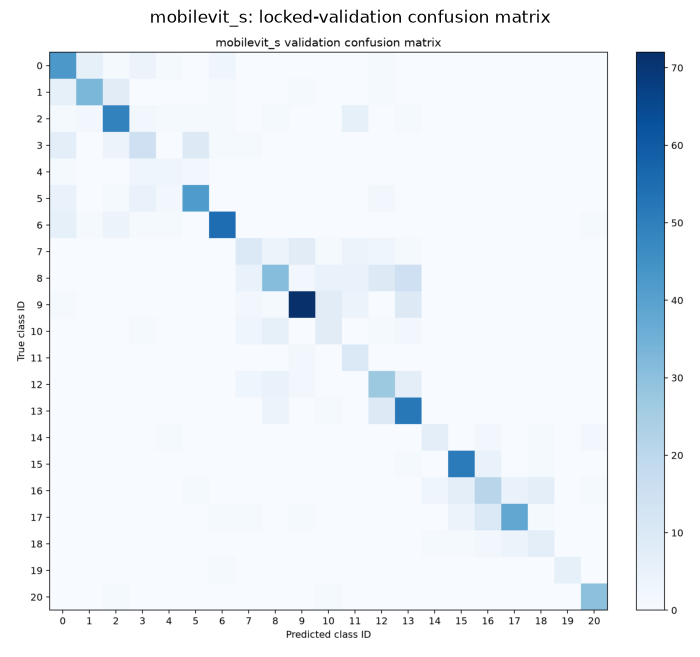

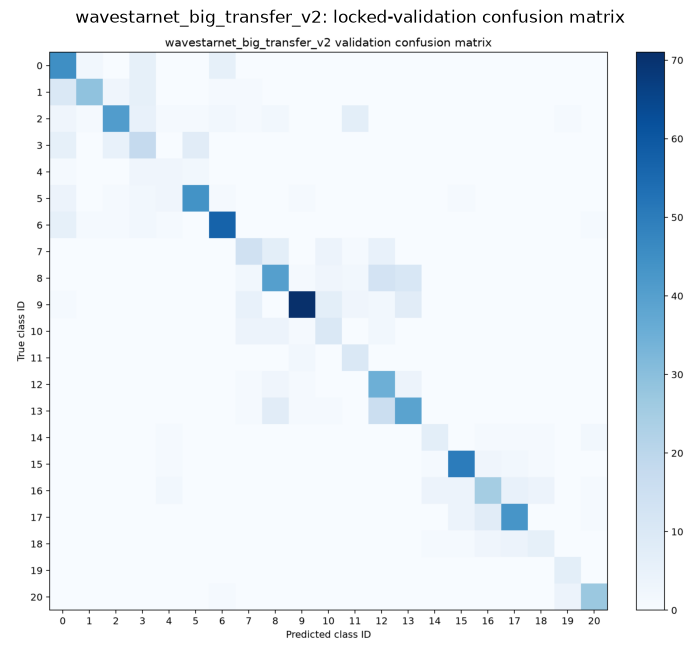

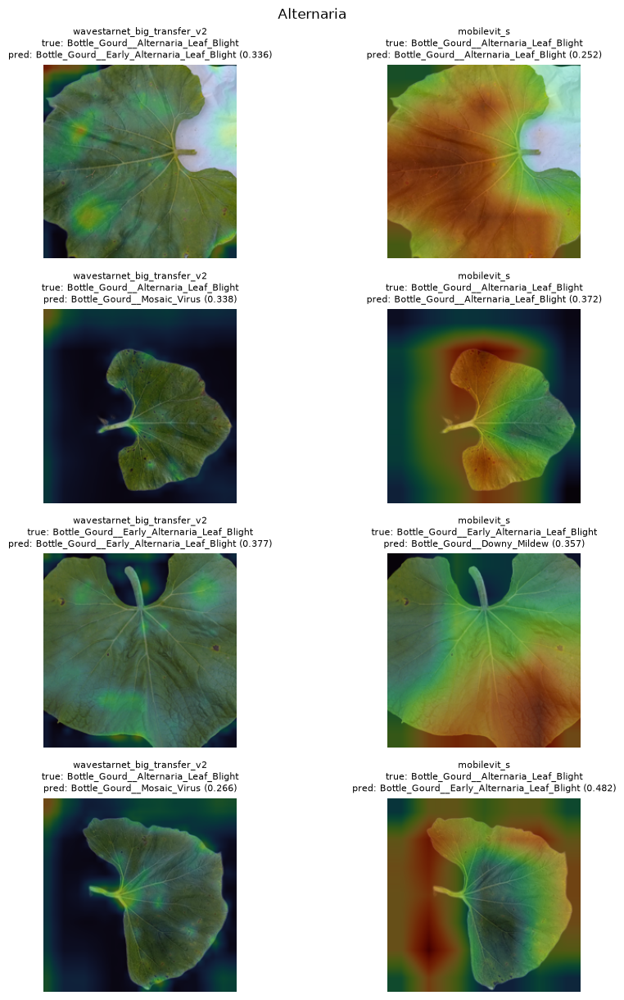

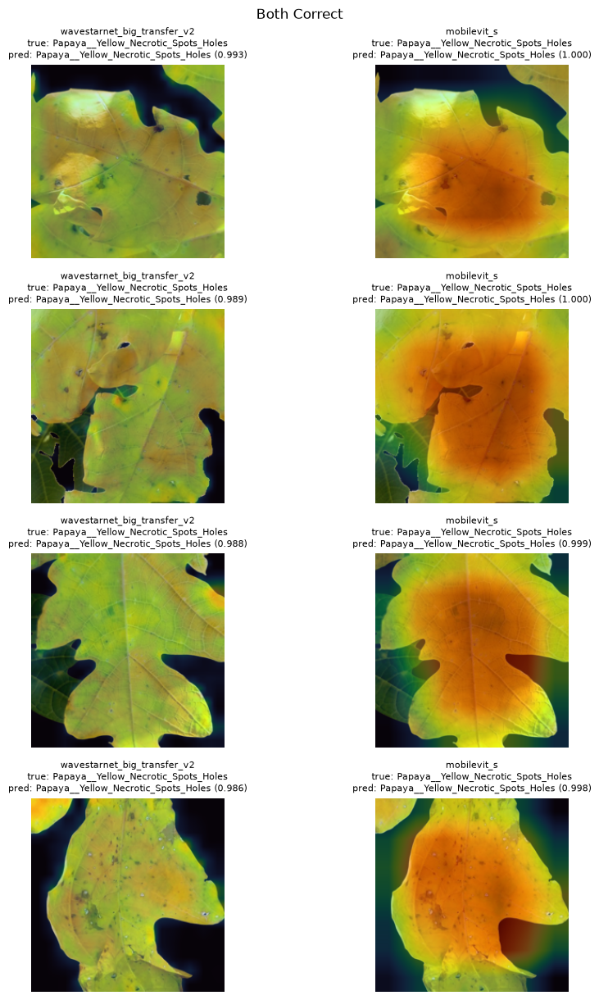

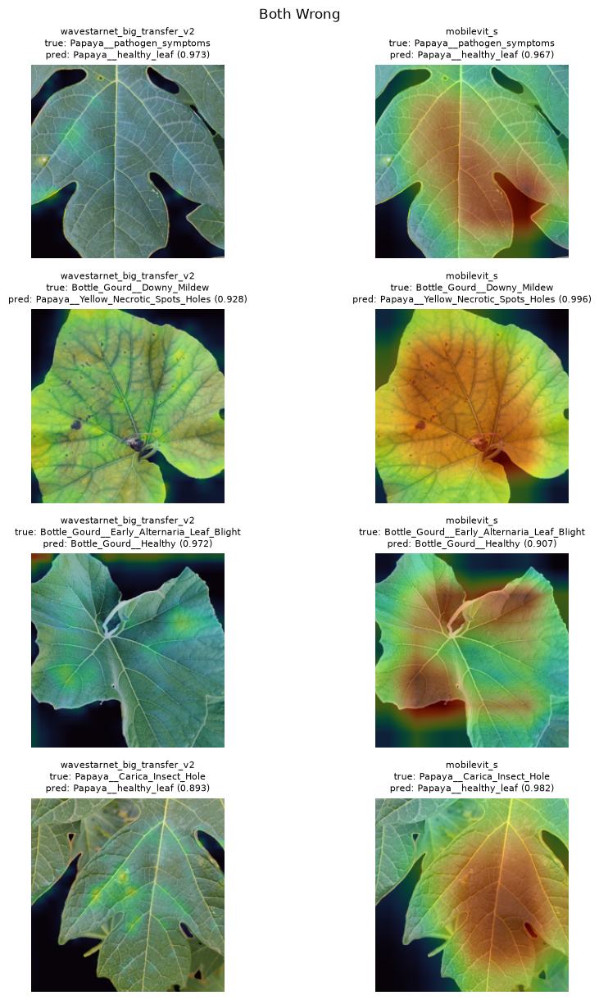

...

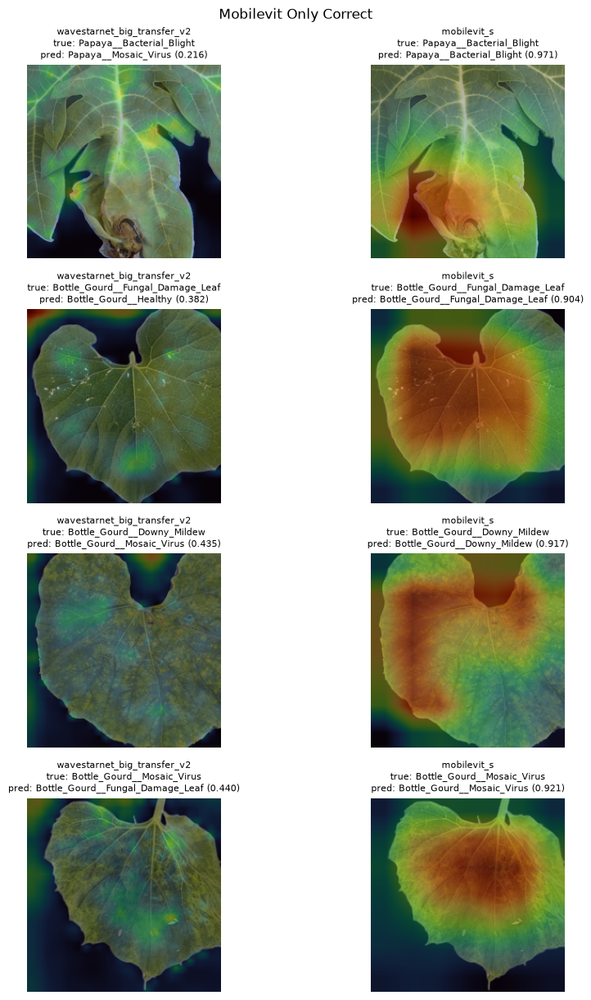

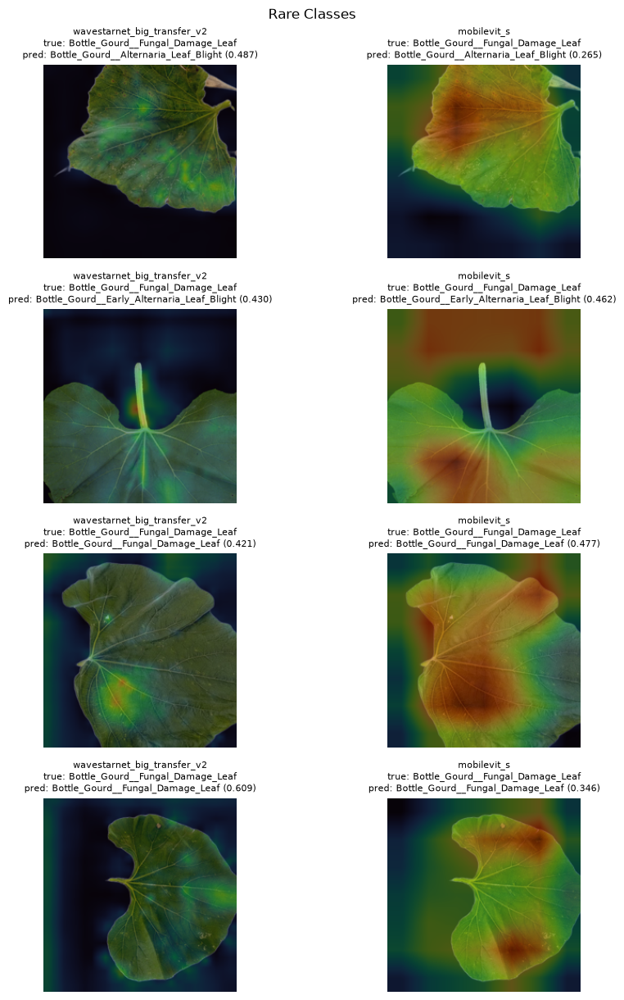

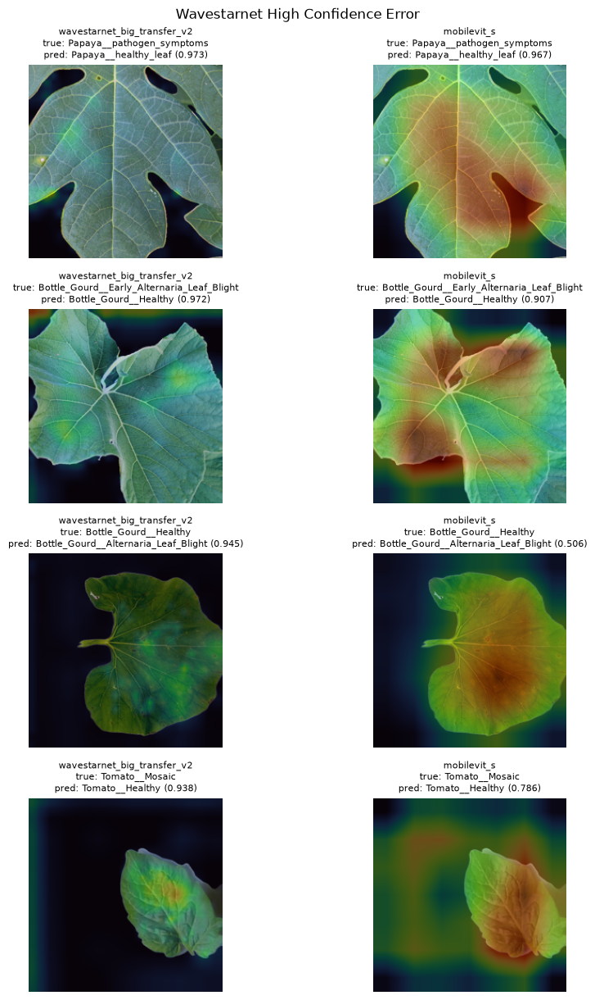

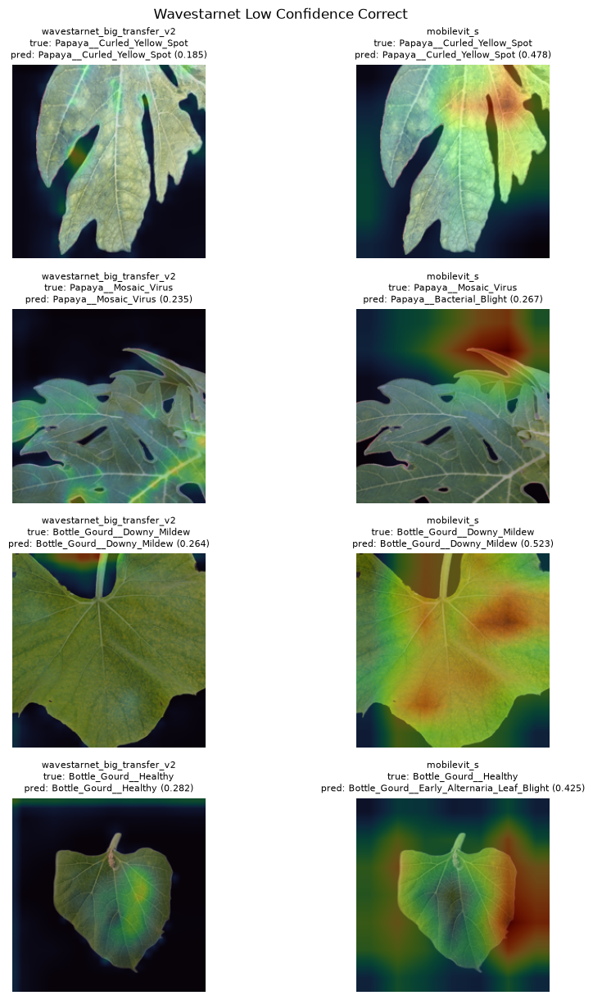

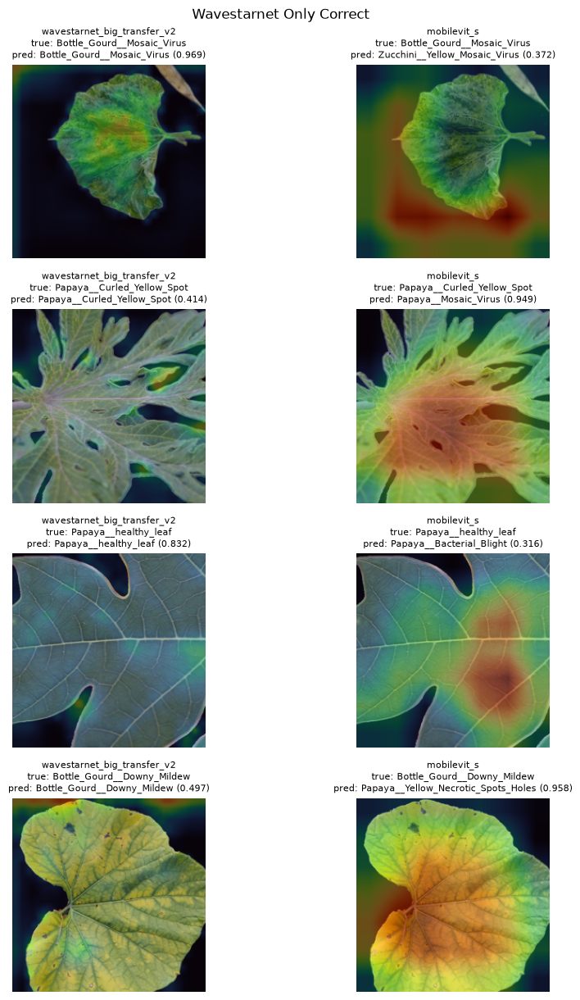

Heatmap diagnostics by model


,predicted_constant_maps,ground_truth_constant_maps,predicted_nonzero_fraction_mean,ground_truth_nonzero_fraction_mean
model_key,,,,
mobilevit_s,0,3,0.993486,0.955963
wavestarnet_big_transfer_v2,0,0,0.976088,0.973749


{
  "output_directory": "/run/media/sha-weed/adc6c87e-0116-4a25-a6e9-8555193c1e51/Research/Agrivision4/agrivision4/results/interpretability/gradcam_validation_v1",
  "prediction_agreement": 0.7497267759562841,
  "prediction_records": 1830,
  "selected_inline_cases": 44,
  "validation_images": 915
}


In [5]:
report_inventory = display_analysis_report(summary)

## Completeness Check

In [6]:
predictions = pd.read_csv(summary.predictions_csv)
expected_images = VERIFY_LIMIT if RUN_MODE == "verify" else 915
expected_records = expected_images * 2

assert summary.validation_count == expected_images
assert len(predictions) == expected_records
assert predictions[["sample_id", "model_key"]].duplicated().sum() == 0
assert predictions["artifact_status"].eq("complete").all()

artifact_columns = [
    "predicted_heatmap",
    "ground_truth_heatmap",
    "predicted_overlay",
    "ground_truth_overlay",
]
for column in artifact_columns:
    missing = [
        value
        for value in predictions[column]
        if not (config.output_dir / value).is_file()
    ]
    assert not missing, f"missing {column} artifacts: {missing[:3]}"

final_status = {
    "run_mode": RUN_MODE,
    "validation_images": summary.validation_count,
    "prediction_records": len(predictions),
    "artifact_columns_verified": artifact_columns,
    "results_directory": str(config.output_dir),
    "executed_notebook_should_be_saved": True,
}
print(json.dumps(final_status, indent=2), flush=True)
print("Analysis complete. Save this notebook to retain all inline output.", flush=True)

{
  "run_mode": "full",
  "validation_images": 915,
  "prediction_records": 1830,
  "artifact_columns_verified": [
    "predicted_heatmap",
    "ground_truth_heatmap",
    "predicted_overlay",
    "ground_truth_overlay"
  ],
  "results_directory": "/run/media/sha-weed/adc6c87e-0116-4a25-a6e9-8555193c1e51/Research/Agrivision4/agrivision4/results/interpretability/gradcam_validation_v1",
  "executed_notebook_should_be_saved": true
}


Analysis complete. Save this notebook to retain all inline output.
